# Section 2 (B): Decision Tree

ML4N - Group Project 4

In this notebook we train the **Decision Tree** detectors (one-vs-rest, one per app) and, as an extra, a **Random
Forest**. We follow the shared rules of `docs/project/SECTION2_RULES.md`, so the results can be compared with the MLP
(A) and the linear models / SVM (C):

- same 80/20 split by `Flow.ID` (`load_train_test`), the test set is not used here;
- same 5 cross-validation folds, grouped by `Flow.ID` and stratified on the app (`get_cv_folds`);
- same validation metric, the **F1 of class 1** (`SCORING`), used to choose the hyperparameters;
- same normalization fitted inside each fold (`with_scaler`) and same results file (`results/section2/decision_tree.csv`).

**Decision trees in short** (Lecture 10). A decision tree is a piece-wise constant model: each internal node tests one
feature against a threshold ($x_j \le t$), each leaf gives a class. It is built top-down and greedily (CART in
scikit-learn): at each node it tries all the features and thresholds and keeps the split with the largest decrease of
impurity, measured with the Gini index $G = 1 - \sum_c p_c^2$ or the entropy $H = -\sum_c p_c \log_2 p_c$ of the class
proportions $p_c$ in the node. The greedy choice does not guarantee the best tree, but it's fast. A deep tree can
isolate every training flow (low bias, high variance, overfitting), a shallow one underfits: the complexity is
controlled with `max_depth`, `min_samples_leaf` (minimum number of flows in a leaf) or cost-complexity pruning
(`ccp_alpha`). These are the hyperparameters we tune with cross-validation.

In [1]:
import os
import sys
from pathlib import Path

# move to the project root, otherwise the relative paths in src/ don't work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# Parallel fits. Each fit copies the training part of the fold (+ the scaled copy, ~0.6 GB), so with all the cores
# the RAM is not enough. LOKY_MAX_CPU_COUNT also limits n_jobs=-1 inside the plot functions of src/evaluation.py.
N_JOBS = 6
os.environ["LOKY_MAX_CPU_COUNT"] = str(N_JOBS)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree

from src.data import APPS, load_train_test, make_ovr_target
from src.evaluation import (
    SCORING, SEED, get_cv_folds, plot_grid_heatmap, plot_validation_curve, save_cv_result, with_scaler,
)

GROUP_APP = "YOUTUBE"  # app assigned to the group (Group ID mod 10), attacked in Section 3-4
PLOTS_DIR = Path("results/plots")  # plots for the report
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

## Data and folds

`load_train_test` reads `model_ready.csv` (~1 minute) and returns the training set (80%) with 64 features, not
scaled. The folds are computed once and used for all the 10 apps.

In [2]:
X_train, X_test, y_train, y_test, groups_train = load_train_test()
folds = get_cv_folds(y_train, groups_train)
FEATURES = X_train.columns

print(f"Training set: {X_train.shape[0]:,} flows x {X_train.shape[1]} features "
      f"({groups_train.nunique():,} distinct Flow.ID)")
print("Validation fold sizes:", [len(val_idx) for _, val_idx in folds])

# share of class 1 for each detector = F1 of a random guess with the same proportions (baseline_stratified)
share = pd.Series({app: make_ovr_target(y_train, app).mean() for app in APPS}, name="positive_share")
share.round(3)

Training set: 403,758 flows x 64 features (222,707 distinct Flow.ID)
Validation fold sizes: [81291, 80792, 80401, 80699, 80575]


YOUTUBE           0.338
AMAZON            0.172
GMAIL             0.080
WINDOWS_UPDATE    0.068
MICROSOFT         0.108
FACEBOOK          0.058
DROPBOX           0.050
SKYPE             0.060
TWITTER           0.036
CLOUDFLARE        0.029
Name: positive_share, dtype: float64

### Does the normalization matter for a tree?

The rules ask to put `LogMinMaxScaler` before every model (`with_scaler`), so we do it. For a tree it should not change
anything: log1p and Min-Max are increasing functions, so they keep the order of the values of each feature. A split
$x_j \le t$ only depends on this order (which flows go left and which go right), so the possible partitions of the
training flows, their impurity and so the chosen splits are the same; only the thresholds are written in a different
scale. This is why the trees "don't need scaling" (Lecture 10, table in Section 8).

We check it on the first fold, with the same tree trained on the raw and on the scaled features. On the full training set the
two trees are identical (same number of leaves, same predictions on the whole validation fold). On a small sample we
saw differences on ~0.05% of the flows: scikit-learn stores the features as float32, and the raw values go up to ~4e9
(`Flow.Bytes.s`), where float32 cannot distinguish close values, so a few thresholds can change. It's a numerical
detail, not a different model.

In [3]:
train_idx, val_idx = folds[0]
y_bin = make_ovr_target(y_train, GROUP_APP)
X_tr, y_tr, X_val = X_train.iloc[train_idx], y_bin.iloc[train_idx], X_train.iloc[val_idx]

tree_scaled = with_scaler(DecisionTreeClassifier(max_depth=10, random_state=SEED)).fit(X_tr, y_tr)
tree_raw = DecisionTreeClassifier(max_depth=10, random_state=SEED).fit(X_tr, y_tr)
same = (tree_scaled.predict(X_val) == tree_raw.predict(X_val)).mean()
print(f"Leaves: scaled {tree_scaled[-1].get_n_leaves()}, raw {tree_raw.get_n_leaves()}")
print(f"Same prediction on {same:.2%} of the validation fold")

Leaves: scaled 469, raw 469
Same prediction on 100.00% of the validation fold


## Grid search

For each app a `GridSearchCV` with the shared folds and `scoring="f1"`. For every combination the tree is trained on
4 folds and scored on the 5th, 5 times; the mean is the validation F1. With `refit=True` the best combination is then
trained again on the whole training set (we use these trees for the feature importances).

The grid:

- `max_depth` in [5, 10, 15, 20, None]: the main complexity knob. `None` = grow until the leaves are pure or reach
  `min_samples_leaf` (on this data a tree without depth limit is 30-55 levels deep).
- `min_samples_leaf` in [1, 10, 100, 1000]: logarithmic range, since it spans orders of magnitude. A big value
  forbids leaves with a few flows, so it smooths the tree in a different way than the depth (a deep but "bushy" tree
  can still have large leaves).
- `class_weight` in [None, "balanced"]: class imbalance as a hyperparameter. "balanced" gives to class 1 the weight
  $n / (2 n_1)$, so in the impurity a positive flow counts as many negatives: the leaves vote for class 1 even when the
  positives are not the majority of the leaf. This moves the trade-off towards recall, which can increase the F1 of
  the small apps (and Section 3 needs a detector with a good recall).

`criterion` is kept at the default (Gini) in the grid and checked afterwards, to keep the search at 40 combinations
(40 x 5 x 10 = 2000 fits of ~20 s each on ~320k flows, with 6 fits in parallel it takes ~1.5 hours). `return_train_score=True` also saves the F1 on the
training folds, to see the overfitting.

In [4]:
param_grid = {
    "model__max_depth": [5, 10, 15, 20, None],
    "model__min_samples_leaf": [1, 10, 100, 1000],
    "model__class_weight": [None, "balanced"],
}

searches = {}
for app in APPS:
    y_bin = make_ovr_target(y_train, app)
    search = GridSearchCV(with_scaler(DecisionTreeClassifier(random_state=SEED)), param_grid, scoring=SCORING,
                          cv=folds, n_jobs=N_JOBS, return_train_score=True)
    search.fit(X_train, y_bin)
    save_cv_result("decision_tree", app, search)
    searches[app] = search
    print(f"{app:15s} validation F1 = {search.best_score_:.3f}  {search.best_params_}")

YOUTUBE         validation F1 = 0.873  {'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 1}
AMAZON          validation F1 = 0.859  {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 10}
GMAIL           validation F1 = 0.685  {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 10}
WINDOWS_UPDATE  validation F1 = 0.899  {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 10}
MICROSOFT       validation F1 = 0.747  {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 10}
FACEBOOK        validation F1 = 0.920  {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 10}
DROPBOX         validation F1 = 0.879  {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 1}
SKYPE           validation F1 = 0.677  {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf'

### Best hyperparameters per app

`train_f1` is the F1 on the training folds and `cv_f1_mean` the one on the validation folds, for the best combination;
`positive_share` is the F1 of a random guess with the same class proportions (the stratified baseline). `depth` and
`n_leaves` are the ones of the tree retrained on the whole training set.

In [5]:
rows = []
for app, search in searches.items():
    i, res = search.best_index_, search.cv_results_
    tree = search.best_estimator_[-1]
    rows.append({
        "app": app,
        "positive_share": share[app],
        "train_f1": res["mean_train_score"][i],
        "cv_f1_mean": res["mean_test_score"][i],
        "cv_f1_std": res["std_test_score"][i],
        "max_depth": str(search.best_params_["model__max_depth"]),
        "min_samples_leaf": search.best_params_["model__min_samples_leaf"],
        "class_weight": search.best_params_["model__class_weight"],
        "depth": tree.get_depth(),
        "n_leaves": tree.get_n_leaves(),
        "fit_time_s": res["mean_fit_time"][i],
        "predict_time_s": res["mean_score_time"][i],
    })
summary = pd.DataFrame(rows).set_index("app").sort_values("cv_f1_mean", ascending=False)
print(f"Mean validation F1 over the 10 apps: {summary['cv_f1_mean'].mean():.3f}")
summary.round(3)

Mean validation F1 over the 10 apps: 0.783


,positive_share,train_f1,cv_f1_mean,cv_f1_std,max_depth,min_samples_leaf,class_weight,depth,n_leaves,fit_time_s,predict_time_s
app,,,,,,,,,,,
FACEBOOK,0.058,0.940,0.920,0.003,20,10,None,20,1585,23.251,0.190
WINDOWS_UPDATE,0.068,0.926,0.899,0.001,None,10,None,31,2412,25.801,0.220
DROPBOX,0.050,0.940,0.879,0.005,20,1,None,20,1576,26.347,0.198
YOUTUBE,0.338,0.950,0.873,0.002,20,1,balanced,20,12287,22.602,0.219
AMAZON,0.172,0.907,0.859,0.004,None,10,None,42,6542,20.790,0.209
CLOUDFLARE,0.029,0.933,0.766,0.011,20,1,None,20,2736,16.461,0.210
MICROSOFT,0.108,0.832,0.747,0.003,None,10,None,44,7060,20.674,0.223
GMAIL,0.080,0.806,0.685,0.004,None,10,None,36,5868,19.701,0.225
SKYPE,0.060,0.789,0.677,0.006,None,10,None,43,5228,20.857,0.196


Comments:
- All the detectors are far above the random guess (F1 = share of positives, 3-34%). The mean validation F1 over the 10
  apps is **0.783**. The variation between folds is small (`cv_f1_std` 0.001-0.011), so the differences between apps
  are not due to the split (remember that `cv_f1_std` is not a confidence interval, the training parts of the folds
  overlap).
- The ranking of the apps mostly follows the EDA. The easiest ones (FACEBOOK 0.92, WINDOWS_UPDATE 0.90, DROPBOX 0.88,
  AMAZON 0.86) are apps with strong single features (port 80, packet sizes, server not answering, inverted flows). The
  hardest ones (TWITTER 0.53, SKYPE 0.68, GMAIL 0.69, MICROSOFT 0.75) are four of the five apps whose best single
  feature had an AUC of only 0.57-0.64 in the EDA. The fifth one, YOUTUBE (0.87), is the exception: no single feature
  separates it, but it is 34% of the flows, so the tree has many examples to learn the combinations of features that
  identify it.
- The best trees are deep: `max_depth` 20 or `None` for all the apps (real depth 20-44, from ~1,600 to ~12,000
  leaves). The regularization that helps is a small `min_samples_leaf` (10 for 7 apps out of 10), while 100 and 1000
  are worse for every app (e.g. TWITTER 0.53 -> 0.35 at best). This is consistent with the EDA: a lot of the information
  is in *specific values* of some features (`Init_Win_bytes_*`, max packet lengths), so the tree needs many small leaves
  to isolate the groups of flows that share a value. A leaf of 100 or 1000 flows mixes them together.
- Overfitting: the gap between training and validation F1 goes from 0.02 (FACEBOOK) to 0.14 (TWITTER). For TWITTER even
  the training F1 is only 0.67: with `min_samples_leaf=10` every leaf has at least 10 flows, and many TWITTER flows end
  up in leaves where other apps are the majority. Flows with exactly the same features as a flow of another app (2.2%
  of all the flows, Section 1) explain only a small part of it: most TWITTER flows are similar, not identical, to flows
  of other apps.
- Efficiency: ~20 s to train a tree on ~320k flows (measured with 6 fits running in parallel, so on a free CPU it's
  faster) and ~0.2 s to classify the ~80k flows of a validation fold: a flow needs at most 20-44 comparisons, one per
  level.

### Effect of `class_weight`

For each app, the best validation F1 with and without `class_weight="balanced"` (best over the other hyperparameters).

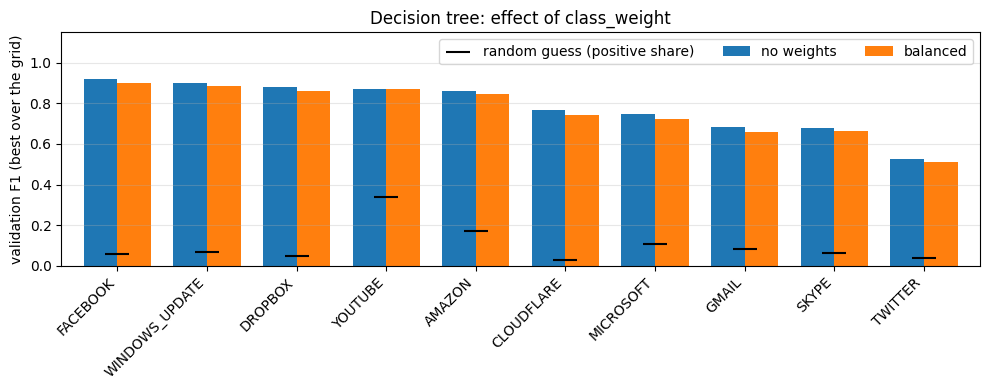

param_model__class_weight,no weights,balanced,gain
app,,,
FACEBOOK,0.920,0.903,-0.018
WINDOWS_UPDATE,0.899,0.886,-0.012
DROPBOX,0.879,0.860,-0.019
YOUTUBE,0.872,0.873,0.001
AMAZON,0.859,0.846,-0.013
CLOUDFLARE,0.766,0.743,-0.022
MICROSOFT,0.747,0.724,-0.023
GMAIL,0.685,0.659,-0.026
SKYPE,0.677,0.666,-0.011


In [6]:
def best_score_by(search, param):
    # best validation F1 for each value of one hyperparameter (max over the others)
    res = pd.DataFrame(search.cv_results_)
    return res.groupby(res[f"param_{param}"].astype(str))["mean_test_score"].max()


cw_effect = pd.DataFrame({app: best_score_by(s, "model__class_weight") for app, s in searches.items()}).T
cw_effect = cw_effect.rename(columns={"None": "no weights", "balanced": "balanced"}).loc[summary.index]
cw_effect["gain"] = cw_effect["balanced"] - cw_effect["no weights"]

fig, ax = plt.subplots(figsize=(10, 4))
cw_effect[["no weights", "balanced"]].plot.bar(ax=ax, width=0.75)
ax.scatter(range(len(cw_effect)), share[cw_effect.index], color="black", marker="_", s=300, zorder=3,
           label="random guess (positive share)")
ax.set_ylabel("validation F1 (best over the grid)")
ax.set_xlabel("")
ax.set_title("Decision tree: effect of class_weight")
ax.set_ylim(0, 1.15)
ax.legend(ncol=3, loc="upper right")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_class_weight.png", dpi=150)
plt.show()
cw_effect.round(3)

In [7]:
# precision and recall of the best tree of 3 apps with and without class weights (other hyperparameters fixed)
rows = []
for app in [GROUP_APP, "SKYPE", "TWITTER"]:
    params = {k.removeprefix("model__"): v for k, v in searches[app].best_params_.items()}
    for cw in [None, "balanced"]:
        params["class_weight"] = cw
        cv = cross_validate(with_scaler(DecisionTreeClassifier(random_state=SEED, **params)), X_train,
                            make_ovr_target(y_train, app), cv=folds, scoring=["precision", "recall", "f1"],
                            n_jobs=N_JOBS)
        rows.append({"app": app, "class_weight": str(cw),
                     **{metric: cv[f"test_{metric}"].mean() for metric in ["precision", "recall", "f1"]}})
pr_weights = pd.DataFrame(rows).set_index(["app", "class_weight"])
pr_weights.round(3)

precision  recall     f1
app     class_weight                          
YOUTUBE None              0.869   0.874  0.872
        balanced          0.846   0.901  0.873
SKYPE   None              0.753   0.615  0.677
        balanced          0.413   0.820  0.549
TWITTER None              0.681   0.431  0.528
        balanced          0.263   0.698  0.382

Comments:
- `class_weight="balanced"` never helps the tree: it's equal for YOUTUBE (+0.001) and it loses 0.01-0.03 of F1 for all
  the other apps. So the grid search chose `None` for 9 apps out of 10.
- This is the opposite of what happens with the linear models (C measured TWITTER F1 0.00 -> 0.12 with "balanced"). A
  linear model has a single boundary, and without weights the majority class pushes it until it predicts always 0. A
  deep tree instead can already build leaves where the app is the majority, also for an app with 3% of the flows.
- The weights only change the vote of the *mixed* leaves. With "balanced" a positive flow weighs $n_0/n_1$ negatives,
  so a leaf is labeled as the app as soon as the app is more than $n_1/n$ of its flows, i.e. more than its share in the
  data: 3.6% for TWITTER, 34% for YOUTUBE. The table above (same folds, the other hyperparameters fixed at the best
  ones) shows the effect: for TWITTER the recall goes from 0.43 to 0.70 but the precision falls from 0.68 to 0.26,
  for SKYPE from 0.62 to 0.82 and from 0.75 to 0.41. Many leaves where the app is a small minority become positive, so
  the false positives grow much more than the true positives. For YOUTUBE the threshold (34%) is not far from 50%, so
  precision and recall change only by ~0.02-0.03 and the F1 stays the same.

### `max_depth` x `min_samples_leaf`

Validation F1 of the grid for the group's app and for the app with the lowest F1 (each cell = best over
`class_weight`).

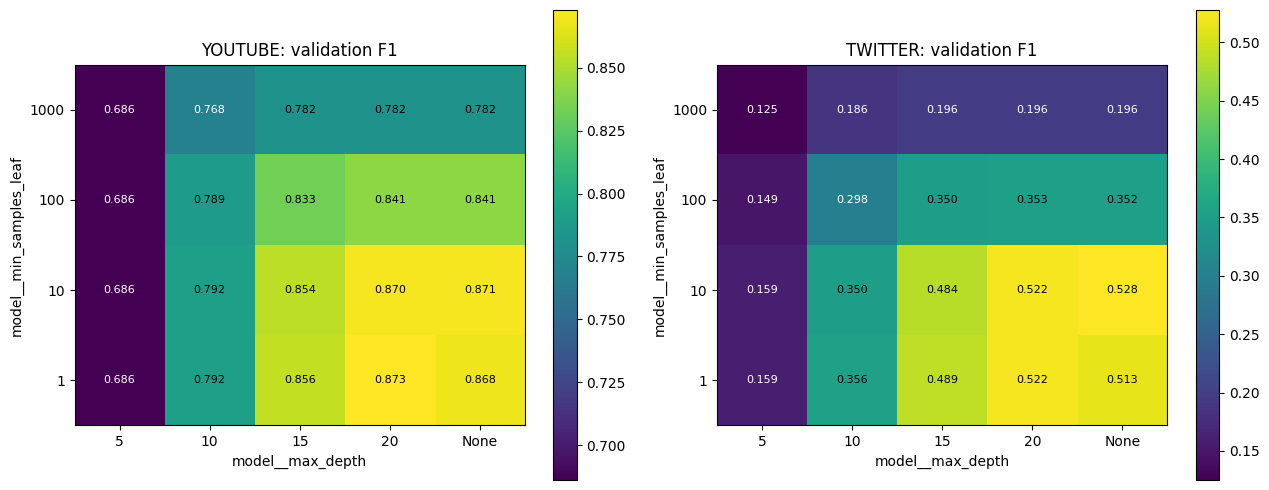

In [8]:
worst_app = summary["cv_f1_mean"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, app in zip(axes, [GROUP_APP, worst_app]):
    plot_grid_heatmap(searches[app], "model__max_depth", "model__min_samples_leaf", ax=ax)
    ax.set_title(f"{app}: validation F1")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_grid_heatmap.png", dpi=150)
plt.show()

Comments: (NOT IMPORTANT)
- `max_depth=5` underfits for every value of `min_samples_leaf` (YOUTUBE 0.69, TWITTER 0.16): 32 leaves are not enough
  to describe these apps.
- The F1 grows with the depth up to 20 and then it's flat: after depth 20 the tree only adds small leaves that change
  the prediction of a few flows.
- `min_samples_leaf` matters much more for the small app: with 1000 TWITTER goes down to 0.20 (from 0.53), YOUTUBE
  only to 0.78 (from 0.87). TWITTER has ~11.6k flows in a training fold, so with leaves of at least 1000 flows its
  small groups always end up mixed with flows of other apps.
- The best region is `max_depth` >= 20 with `min_samples_leaf` 1-10, and in that region the differences are below 0.01.

## Validation curve: `max_depth`

`max_depth` is the most important hyperparameter of the tree. We move it from 2 to `None` with the other two fixed at
their best value, and plot the training and validation F1 (same folds). 

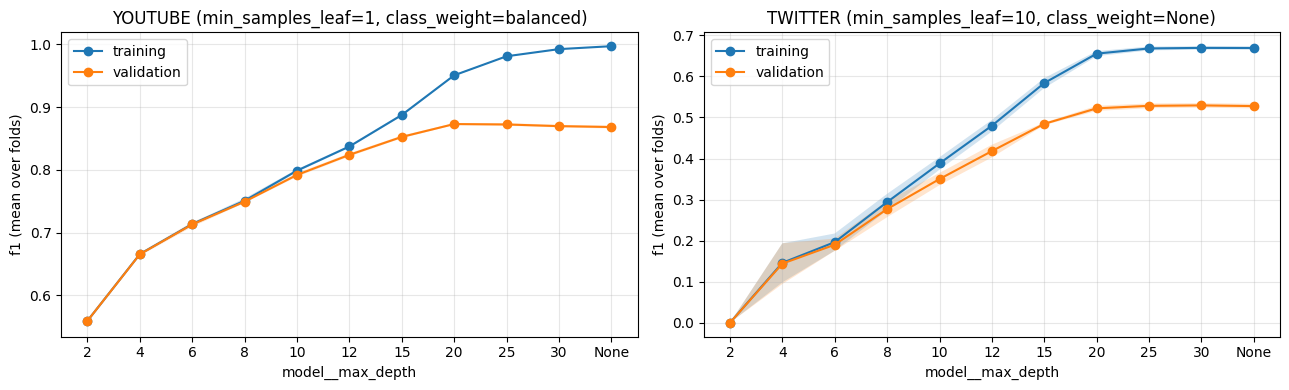

In [9]:
depth_range = [2, 4, 6, 8, 10, 12, 15, 20, 25, 30, None]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, app in zip(axes, [GROUP_APP, worst_app]):
    best = searches[app].best_params_
    estimator = with_scaler(DecisionTreeClassifier(min_samples_leaf=best["model__min_samples_leaf"],
                                                   class_weight=best["model__class_weight"], random_state=SEED))
    plot_validation_curve(estimator, X_train, make_ovr_target(y_train, app), "model__max_depth", depth_range,
                          folds, ax=ax)
    ax.set_title(f"{app} (min_samples_leaf={best['model__min_samples_leaf']}, "
                 f"class_weight={best['model__class_weight']})")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_validation_curve_depth.png", dpi=150)
plt.show()

Comments:
- YOUTUBE: up to depth ~10 the training and validation F1 grow together and are almost equal: the model is too simple
  (**underfitting**, high bias). After that they separate: the training F1 goes to 1.0 (with `min_samples_leaf=1` a
  tree without limits isolates every training flow), while the validation F1 stops at 0.873 at depth 20 and then
  decreases a bit (0.868 with `None`). This is **overfitting**: the extra levels fit noise of the training folds. It's
  mild here because each extra leaf only affects a few flows, so the validation F1 decreases slowly.
- TWITTER (`min_samples_leaf=10`): same behaviour, but the training F1 stops at ~0.67. The leaf size limits how much the
  tree can memorize, so the gap stays around 0.14 and the validation F1 is flat (~0.53) from depth 20.
- So the depth chosen by the grid search (20 or `None`) is at the beginning of the flat part of the validation curve.

### Pruning: `ccp_alpha`

Instead of stopping the growth early (`max_depth`, `min_samples_leaf`), a tree can be grown completely and then pruned: minimal cost-complexity pruning removes the subtrees whose decrease of (weighted) impurity per
additional leaf is smaller than `ccp_alpha`. We check if it gives something more on the group's app, on a
logarithmic range (`ccp_alpha` close to 0 = unpruned tree).

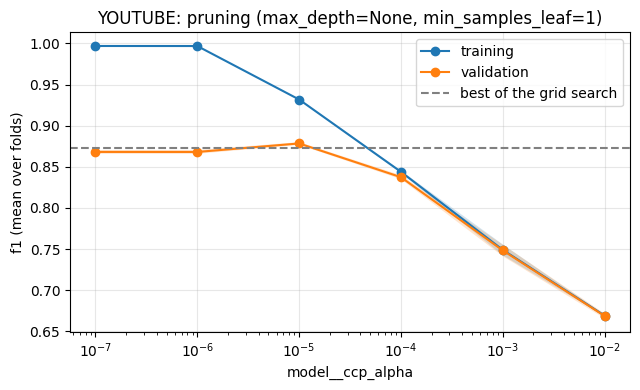

In [10]:
alpha_range = np.logspace(-7, -2, 6)
best = searches[GROUP_APP].best_params_
estimator = with_scaler(DecisionTreeClassifier(class_weight=best["model__class_weight"], random_state=SEED))
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_validation_curve(estimator, X_train, make_ovr_target(y_train, GROUP_APP), "model__ccp_alpha", alpha_range,
                      folds, ax=ax)
ax.axhline(searches[GROUP_APP].best_score_, color="gray", linestyle="--", label="best of the grid search")
ax.set_title(f"{GROUP_APP}: pruning (max_depth=None, min_samples_leaf=1)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_validation_curve_ccp_alpha.png", dpi=150)
plt.show()

Comments: with very small `ccp_alpha` (1e-7, 1e-6) the tree is practically unpruned (training F1 ~1, validation 0.868,
like `max_depth=None`). With `ccp_alpha=1e-5` the pruning removes the subtrees that fit noise: the training F1 goes
down to 0.93 and the validation F1 goes **up** to 0.878, slightly better than the best of the grid search (0.873, the
fold std is ~0.002). With bigger values the pruning removes useful splits too and the tree underfits (training and
validation equal and decreasing). So pruning and limiting the depth / leaf size give almost the same result: they are
two ways to control the same bias-variance trade-off. We don't put `ccp_alpha` in the grid (it would multiply the cost
of the search), the gain is small.

### Gini or entropy?

The best hyperparameters of each app with `criterion="entropy"` instead of Gini (same folds). These hyperparameters were
chosen with Gini, so if anything the comparison is a bit in favor of Gini.

In [11]:
rows = []
for app, search in searches.items():
    params = {k.removeprefix("model__"): v for k, v in search.best_params_.items()}
    cv = cross_validate(with_scaler(DecisionTreeClassifier(criterion="entropy", random_state=SEED, **params)),
                        X_train, make_ovr_target(y_train, app), cv=folds, scoring=SCORING, n_jobs=N_JOBS)
    rows.append({"app": app, "gini": search.best_score_, "entropy": cv["test_score"].mean()})
criterion_cmp = pd.DataFrame(rows).set_index("app")
criterion_cmp["diff"] = criterion_cmp["entropy"] - criterion_cmp["gini"]
criterion_cmp.round(3)

,gini,entropy,diff
app,,,
YOUTUBE,0.873,0.872,-0.001
AMAZON,0.859,0.859,-0.000
GMAIL,0.685,0.689,0.004
WINDOWS_UPDATE,0.899,0.903,0.004
MICROSOFT,0.747,0.742,-0.004
FACEBOOK,0.920,0.921,0.001
DROPBOX,0.879,0.882,0.003
SKYPE,0.677,0.692,0.016
TWITTER,0.528,0.543,0.015


Comments: for 8 apps out of 10 the difference between Gini and entropy is within ±0.005, the same order of the
variation between folds. For SKYPE and TWITTER entropy is better by ~0.015, more than twice their `cv_f1_std`.

## Feature importances

scikit-learn's `feature_importances_` (mean decrease of impurity, MDI) sums, for each feature, the impurity decrease of
all the splits on that feature, weighted by the number of flows that reach the node, normalized to 1. We use the trees
retrained on the whole training set with the best hyperparameters of each app. Below, the 20 features with the highest
mean importance over the 10 apps.

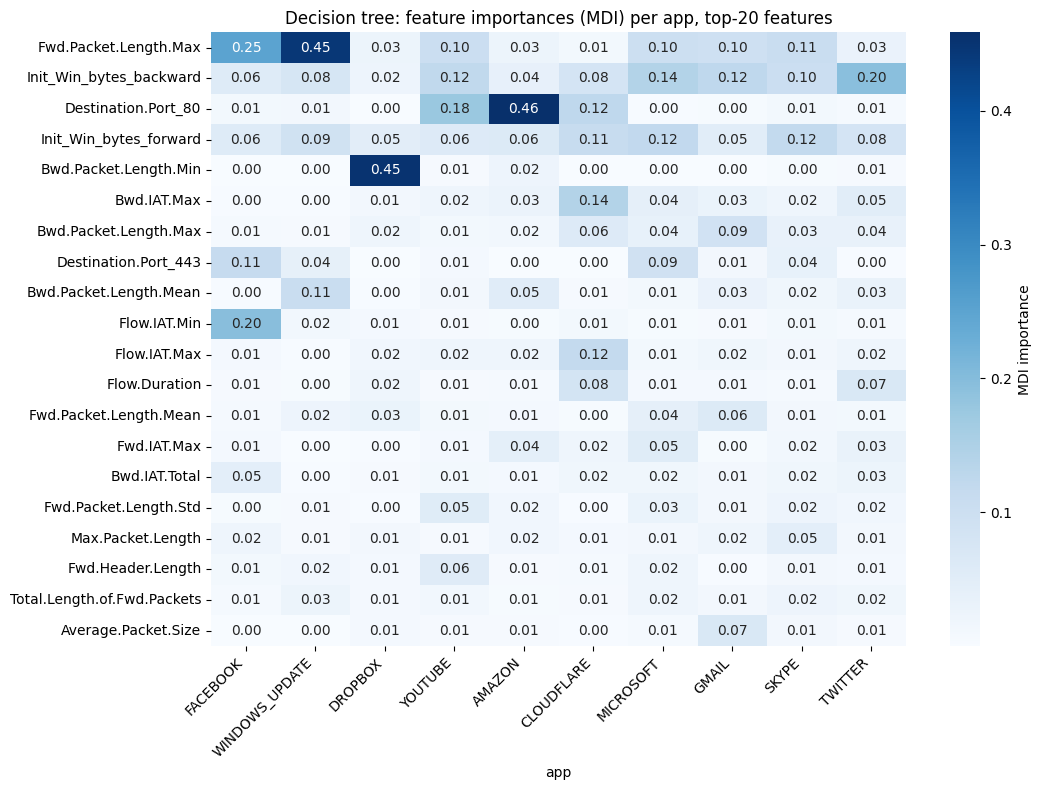

In [12]:
importances = pd.DataFrame({app: s.best_estimator_[-1].feature_importances_ for app, s in searches.items()},
                           index=FEATURES)
top = importances.mean(axis=1).nlargest(20).index

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(importances.loc[top, summary.index], cmap="Blues", annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "MDI importance"})
ax.set_title("Decision tree: feature importances (MDI) per app, top-20 features")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_feature_importances.png", dpi=150)
plt.show()

Comments, compared with the EDA (Section 1.3) (STEFANO WANTS TO IMPROVE THIS PART FOR THE REPORT, CONFRONTING THIS TABLE WITH THE AUC AND MI TABLE THAT ARE IN THE EDA ANALYSIS):
- The two initial windows are used by all the detectors: `Init_Win_bytes_backward` + `Init_Win_bytes_forward` together
  take from 0.07 (DROPBOX) to 0.28 (TWITTER) of the importance, and `Init_Win_bytes_backward` is the first feature for
  TWITTER (0.20), MICROSOFT and GMAIL (`Init_Win_bytes_forward` for SKYPE). The EDA found that their information is in
  specific values (signatures of the server or of the proxy), and a tree can isolate a value with two splits. As noted
  in the EDA, this is also a risk of shortcut learning: a different configuration of the servers would change these
  values.
- `Destination.Port_80` is the main feature of AMAZON (0.46) and is important for CLOUDFLARE (0.12) and YOUTUBE (0.18),
  as expected from the port table of the EDA (port 80 for the CDN traffic of AMAZON and CLOUDFLARE, almost never for
  YOUTUBE).
- `Fwd.Packet.Length.Max` is the main feature of WINDOWS_UPDATE (0.45) and FACEBOOK (0.25): the max packet sizes were
  the other "specific values" features of the EDA (fixed-size protocol messages). FACEBOOK also uses `Flow.IAT.Min`
  (0.20) and `Destination.Port_443`.
- CLOUDFLARE uses timing features (`Bwd.IAT.Max`, `Flow.IAT.Max`, `Flow.Duration`), consistent with the fixed max gap
  of 46 s that we saw in its ECDF.
- DROPBOX is almost entirely `Bwd.Packet.Length.Min` (0.45), a feature that the EDA did not point out (there DROPBOX was
  characterized by long idle periods, `Idle.Max` is its second feature here, and by the inverted flows). We check it
  below.
- In general the MDI shows what *this tree* used: among correlated features (e.g. the many packet length statistics)
  the tree picks one and the others get ~0, so a low MDI doesn't mean that a feature has no information.

### DROPBOX and `Bwd.Packet.Length.Min`

The min packet length in a direction is 0 as soon as one packet has no payload (like a pure ACK), and in Section 1 it
was 0 in 83-88% of the flows. Here we look at how often the min backward length is not 0, per app, and for DROPBOX
separately for the flows with `Destination.Port_Other` = 1, which for DROPBOX are the inverted flows of Section 1.2
(server port in `Source.Port`, so "backward" is the client -> server direction).

In [13]:
nonzero_min = X_train["Bwd.Packet.Length.Min"] > 0
is_dropbox = y_train == "DROPBOX"
by_port = nonzero_min[is_dropbox].groupby(X_train.loc[is_dropbox, "Destination.Port_Other"]).mean()
print(f"DROPBOX flows with Bwd.Packet.Length.Min > 0: {by_port[1]:.1%} of the inverted flows (Port_Other = 1), "
      f"{by_port[0]:.1%} of the others")
nonzero_min.groupby(y_train).mean().sort_values(ascending=False).rename("share_bwd_min_nonzero").round(3)

DROPBOX flows with Bwd.Packet.Length.Min > 0: 76.1% of the inverted flows (Port_Other = 1), 9.2% of the others


label
DROPBOX           0.522
SKYPE             0.169
GMAIL             0.157
WINDOWS_UPDATE    0.133
YOUTUBE           0.115
TWITTER           0.113
MICROSOFT         0.094
FACEBOOK          0.062
AMAZON            0.032
CLOUDFLARE        0.014
Name: share_bwd_min_nonzero, dtype: float64

Comments: 52% of the DROPBOX flows have a non-zero min backward length, against 1-17% for the other apps, and inside
DROPBOX it's 76% of the inverted flows and 9% of the others. So the tree uses this feature to recognize the inverted
DROPBOX flows: there the backward direction is the client, and in most of them every packet sent by the client carries
data. The EDA found the inverted flows through the port (`Destination.Port_Other` is the third feature of DROPBOX
here, 0.08), the tree found a feature that separates them better. Note that this is a property of how CICFlowMeter
captured these flows (the beginning of the connection is missing) more than of the app, so it's another possible
shortcut.

### MDI vs permutation importance (UNIMPORTANT, TO BE REMOVED)

The MDI is computed on the training data and it favours the features with many distinct values (they offer more
thresholds, so they are chosen more often also by chance, and in deep trees part of their importance comes from splits
that only fit noise). The **permutation importance** does not have this problem: on held-out data we shuffle one
feature at a time and measure how much the F1 drops. Here we compute it for the group's app on the first validation
fold, with the tree trained on the other 4 folds (5 shuffles per feature). With correlated features (e.g. the different
packet length statistics) it has two problems: the tree can use a correlated feature in place of the shuffled one
(the importance is underestimated), and the shuffled values create flows that can't exist, like a backward mean
larger than the backward max, where the tree can do anything (the importance is overestimated).

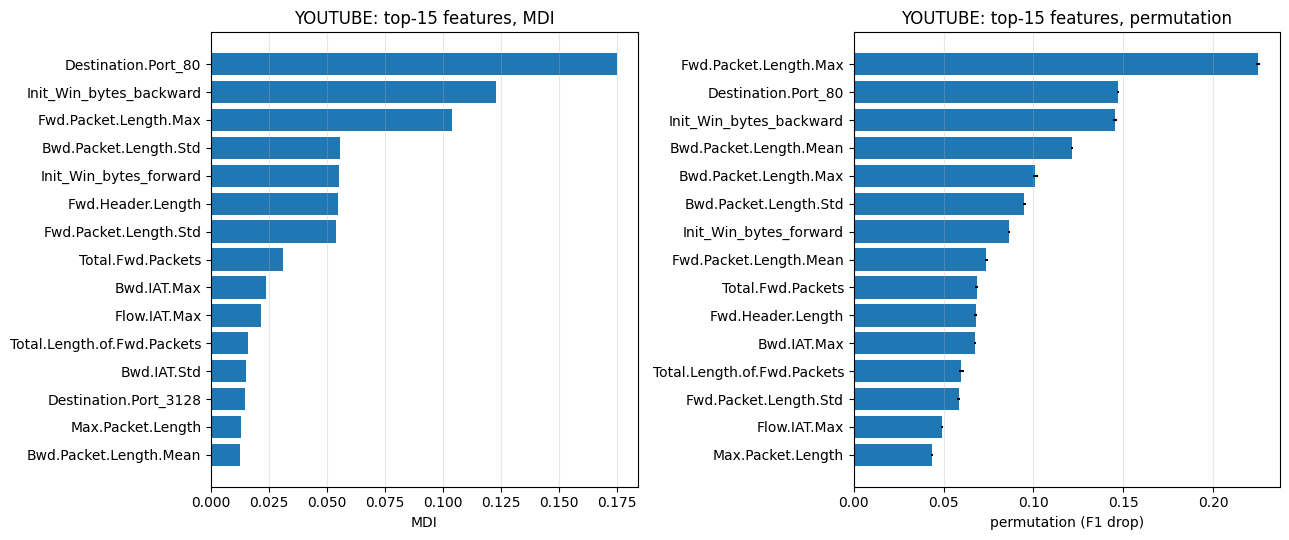

,MDI,permutation (F1 drop),permutation std
Fwd.Packet.Length.Max,0.1041,0.2251,0.0009
Destination.Port_80,0.1753,0.1471,0.0005
Init_Win_bytes_backward,0.1231,0.1456,0.0010
Bwd.Packet.Length.Mean,0.0126,0.1214,0.0007
Bwd.Packet.Length.Max,0.0107,0.1011,0.0013
Bwd.Packet.Length.Std,0.0557,0.0950,0.0007
Init_Win_bytes_forward,0.0551,0.0865,0.0004
Fwd.Packet.Length.Mean,0.0096,0.0738,0.0009
Total.Fwd.Packets,0.0309,0.0684,0.0008
Fwd.Header.Length,0.0549,0.0680,0.0009


In [14]:
train_idx, val_idx = folds[0]
y_bin = make_ovr_target(y_train, GROUP_APP)
pipe = with_scaler(DecisionTreeClassifier(random_state=SEED))
pipe.set_params(**searches[GROUP_APP].best_params_)
pipe.fit(X_train.iloc[train_idx], y_bin.iloc[train_idx])
perm = permutation_importance(pipe, X_train.iloc[val_idx], y_bin.iloc[val_idx], scoring=SCORING, n_repeats=5,
                              random_state=SEED, n_jobs=N_JOBS)
imp_cmp = pd.DataFrame({"MDI": pipe[-1].feature_importances_, "permutation (F1 drop)": perm.importances_mean,
                        "permutation std": perm.importances_std}, index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, col in zip(axes, ["MDI", "permutation (F1 drop)"]):
    top15 = imp_cmp[col].nlargest(15)[::-1]
    xerr = imp_cmp.loc[top15.index, "permutation std"] if col.startswith("permutation") else None
    ax.barh(top15.index, top15, xerr=xerr, color="tab:blue")
    ax.set_xlabel(col)
    ax.grid(True, axis="x", alpha=0.3)
    ax.set_title(f"{GROUP_APP}: top-15 features, {col.split(' ')[0]}")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_mdi_vs_permutation.png", dpi=150)
plt.show()
imp_cmp.sort_values("permutation (F1 drop)", ascending=False).head(15).round(4)

Comments (YOUTUBE):
- The two measures agree on the top-3: `Fwd.Packet.Length.Max` (shuffling it decreases the validation F1 by 0.23),
  `Destination.Port_80` and `Init_Win_bytes_backward` (~0.15 each). So the importance of `Init_Win_bytes_backward`
  is not just the bias of the MDI towards features with many values: on unseen flows the detector really depends on it.
- The permutation importance gives much more weight to the backward packet sizes (`Bwd.Packet.Length.Mean` and `.Max`,
  0.10-0.12 vs an MDI of ~0.01). These features are used in many splits deep in the tree, on small nodes, so each split
  decreases the impurity of the training data only a little (low MDI); but a flow passes through some of them, and
  with a shuffled value it can end in a wrong leaf. Shuffling one of them also creates impossible combinations with the
  other backward statistics, so for these features the permutation importance probably overestimates how much the
  detector needs them: the truth is somewhere between the two measures.
- The std over the 5 shuffles is ~0.001, so the ranking is stable (with ~80k validation flows).

## A small tree for interpretation

The tuned trees have thousands of leaves, so they can't be read. To see what the first splits do, we train a tree of
depth 3 for the group's app on the whole training set. We use the raw features: as checked above the splits are the
same, but the thresholds are in the original units (bytes, microseconds, ...). Each node shows the share of flows that
reach it and the class proportions (`value`, weighted if `class_weight="balanced"`).

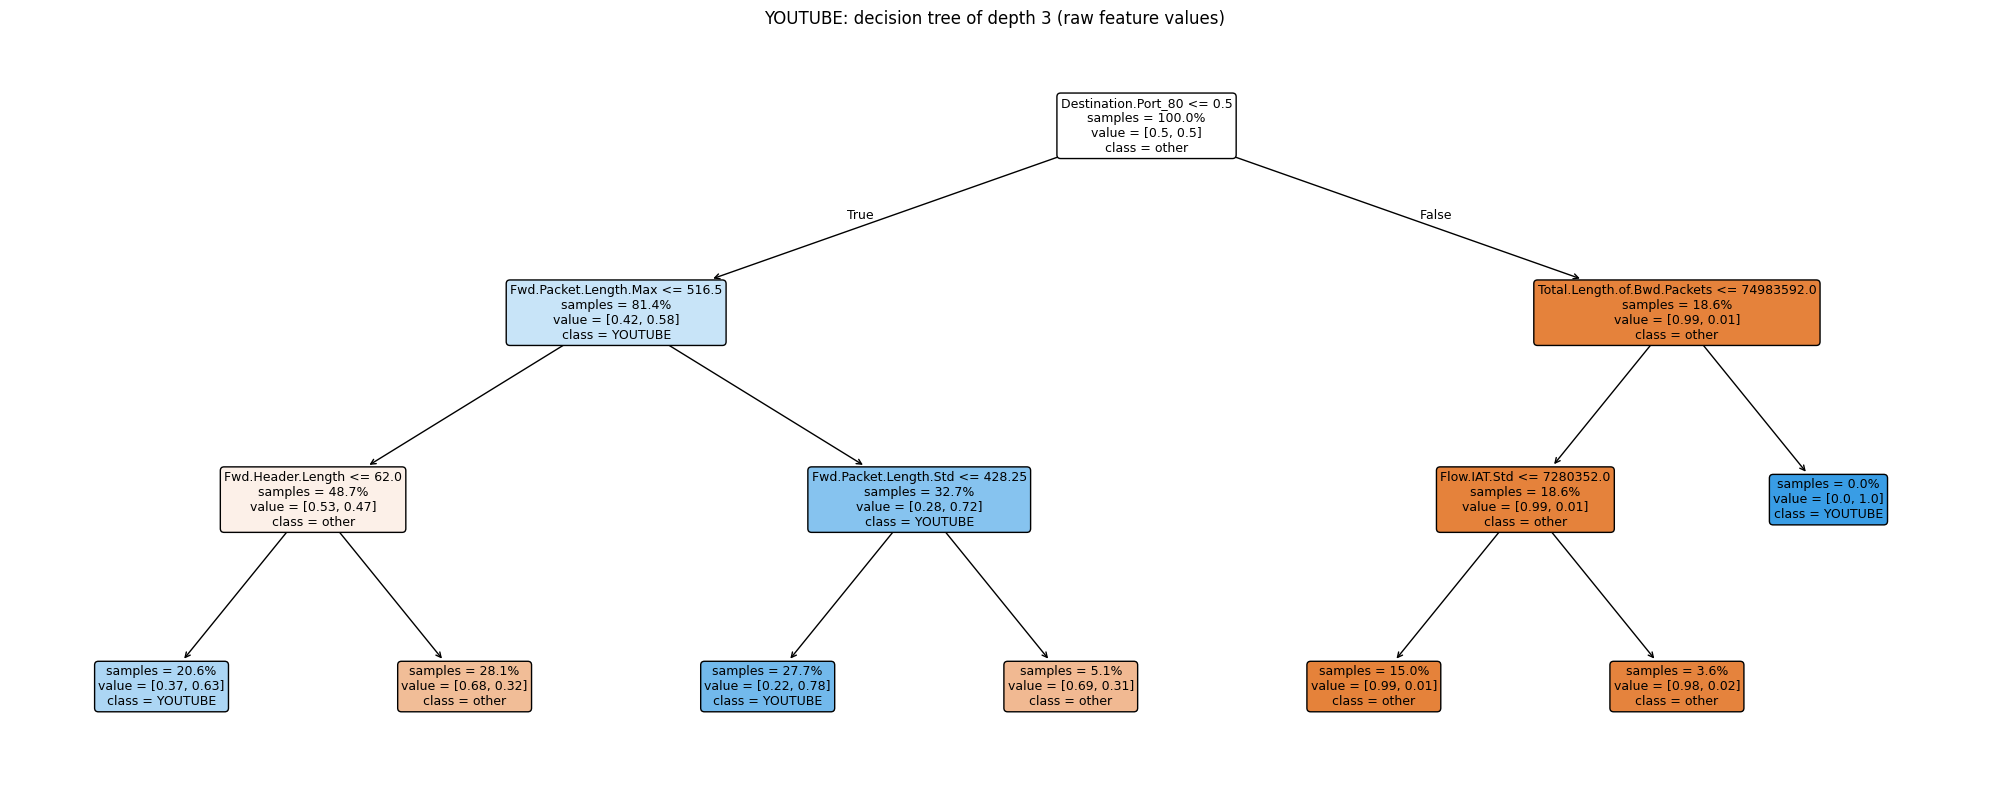

In [15]:
small_tree = DecisionTreeClassifier(max_depth=3, class_weight=searches[GROUP_APP].best_params_["model__class_weight"],
                                    random_state=SEED)
small_tree.fit(X_train, make_ovr_target(y_train, GROUP_APP))
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(small_tree, feature_names=list(FEATURES), class_names=["other", GROUP_APP], filled=True, rounded=True,
          proportion=True, impurity=False, precision=2, fontsize=9, ax=ax)
ax.set_title(f"{GROUP_APP}: decision tree of depth 3 (raw feature values)")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "tree_depth3.png", dpi=150)
plt.show()

Comments: the root splits on `Destination.Port_80`: on port 80 there is almost no YOUTUBE (1% of the weight), so the
right part of the tree is "other". Among the other flows, YOUTUBE is more frequent when the max forward packet is
small (<= 516 bytes) and the flow is very short (`Fwd.Header.Length` <= 62, i.e. 1-3 forward packets), or when the
max forward packet is bigger but with a small std. With only 3 levels the tree is readable, but it is far from the
tuned one: from the validation curve a tree of depth 4 has a validation F1 of ~0.67, against 0.873 at depth 20.

## Random Forest
A Random Forest averages $K$ trees, each trained on a random subset
of the flows and choosing each split among a random subset of the features. The trees are deep but different from each other, so their vote has a much lower variance than a single tree.

To keep the cost reasonable:

- `n_estimators=100`, the nummber of tree, checked with the curve below on the group's app;
- `max_features="sqrt"` (8 of the 64 features at each split, the usual value for classification);
- `max_samples=0.3`: each tree sees a bootstrap sample of 30% of the training part of the fold (~100k flows);
- grid only on `max_depth` in [20, None] and `class_weight` in [None, "balanced_subsample"] (the weights are computed
  on the bootstrap sample of each tree).

In [16]:
rf_grid = {
    "model__max_depth": [20, None],
    "model__class_weight": [None, "balanced_subsample"],
}
rf_notes = "extra: n_estimators=100, max_features=sqrt, max_samples=0.3"

rf_searches = {}
for app in APPS:
    rf = RandomForestClassifier(n_estimators=100, max_features="sqrt", max_samples=0.3, random_state=SEED, n_jobs=1)
    search = GridSearchCV(with_scaler(rf), rf_grid, scoring=SCORING, cv=folds, n_jobs=N_JOBS, refit=False)
    search.fit(X_train, make_ovr_target(y_train, app))
    save_cv_result("random_forest", app, search, notes=rf_notes)
    rf_searches[app] = search
    print(f"{app:15s} validation F1 = {search.best_score_:.3f}  {search.best_params_}")

YOUTUBE         validation F1 = 0.880  {'model__class_weight': None, 'model__max_depth': None}
AMAZON          validation F1 = 0.863  {'model__class_weight': None, 'model__max_depth': None}
GMAIL           validation F1 = 0.673  {'model__class_weight': None, 'model__max_depth': None}
WINDOWS_UPDATE  validation F1 = 0.891  {'model__class_weight': None, 'model__max_depth': None}
MICROSOFT       validation F1 = 0.711  {'model__class_weight': None, 'model__max_depth': None}
FACEBOOK        validation F1 = 0.914  {'model__class_weight': None, 'model__max_depth': None}
DROPBOX         validation F1 = 0.882  {'model__class_weight': None, 'model__max_depth': None}
SKYPE           validation F1 = 0.639  {'model__class_weight': None, 'model__max_depth': None}
TWITTER         validation F1 = 0.415  {'model__class_weight': 'balanced_subsample', 'model__max_depth': 20}
CLOUDFLARE      validation F1 = 0.741  {'model__class_weight': None, 'model__max_depth': None}


In [17]:
rf_cmp = pd.DataFrame({
    "decision_tree": summary["cv_f1_mean"],
    "random_forest": pd.Series({app: s.best_score_ for app, s in rf_searches.items()}),
    "tree_fit_s": summary["fit_time_s"],
    "forest_fit_s": pd.Series({app: s.cv_results_["mean_fit_time"][s.best_index_] for app, s in rf_searches.items()}),
    "tree_predict_s": summary["predict_time_s"],
    "forest_predict_s": pd.Series({app: s.cv_results_["mean_score_time"][s.best_index_]
                                   for app, s in rf_searches.items()}),
})
rf_cmp["gain"] = rf_cmp["random_forest"] - rf_cmp["decision_tree"]
rf_cmp.loc["MEAN"] = rf_cmp.mean()
rf_cmp.round(3)

,decision_tree,random_forest,tree_fit_s,forest_fit_s,tree_predict_s,forest_predict_s,gain
AMAZON,0.859,0.863,20.790,63.561,0.209,1.092,0.004
CLOUDFLARE,0.766,0.741,16.461,48.679,0.210,0.644,-0.025
DROPBOX,0.879,0.882,26.347,83.235,0.198,0.741,0.003
FACEBOOK,0.920,0.914,23.251,65.728,0.190,0.749,-0.006
GMAIL,0.685,0.673,19.701,59.130,0.225,1.165,-0.012
MICROSOFT,0.747,0.711,20.674,62.634,0.223,1.158,-0.035
SKYPE,0.677,0.639,20.857,67.902,0.196,1.006,-0.038
TWITTER,0.528,0.415,19.865,55.890,0.207,0.733,-0.113
WINDOWS_UPDATE,0.899,0.891,25.801,64.817,0.220,0.840,-0.008
YOUTUBE,0.873,0.880,22.602,65.403,0.219,1.232,0.007


 ## -----------------UNIMPORTANT, IGNORE-------------------

In [18]:
# precision and recall: best tree vs best forest (same folds)
rows = []
for app in [GROUP_APP, "SKYPE", "TWITTER"]:
    tree_cw = str(searches[app].best_params_["model__class_weight"])
    rows.append({"app": app, "model": f"tree (class_weight={tree_cw})", **pr_weights.loc[(app, tree_cw)].to_dict()})
    params = {k.removeprefix("model__"): v for k, v in rf_searches[app].best_params_.items()}
    rf = RandomForestClassifier(n_estimators=100, max_features="sqrt", max_samples=0.3, random_state=SEED, n_jobs=1,
                                **params)
    cv = cross_validate(with_scaler(rf), X_train, make_ovr_target(y_train, app), cv=folds,
                        scoring=["precision", "recall", "f1"], n_jobs=N_JOBS)
    rows.append({"app": app, "model": f"forest (class_weight={params['class_weight']})",
                 **{metric: cv[f"test_{metric}"].mean() for metric in ["precision", "recall", "f1"]}})
pd.DataFrame(rows).set_index(["app", "model"]).round(3)

precision  recall     f1
app     model                                                             
YOUTUBE tree (class_weight=balanced)                  0.846   0.901  0.873
        forest (class_weight=None)                    0.895   0.865  0.880
SKYPE   tree (class_weight=None)                      0.753   0.615  0.677
        forest (class_weight=None)                    0.943   0.484  0.639
TWITTER tree (class_weight=None)                      0.681   0.431  0.528
        forest (class_weight=balanced_subsample)      0.371   0.471  0.415

Comments:
- With our configuration the Random Forest is **not** better than the single tree: mean F1 0.761 vs 0.783. It's
  slightly better only for YOUTUBE (+0.007), AMAZON and DROPBOX (+0.003-0.004), and much worse for TWITTER (-0.11),
  SKYPE and MICROSOFT (-0.04). It is also ~3 times slower to train and ~4-5 times slower to predict (0.94 s vs 0.21 s
  per validation fold, 100 trees to evaluate instead of 1).
- The table above shows what goes wrong for the small apps. Without class weights (SKYPE) the forest is much more
  conservative than the tree: precision 0.94 instead of 0.75, but recall 0.48 instead of 0.62. The forest predicts
  the app only if the mean probability of its 100 trees is above 0.5, and for a rare app the trees, each trained on a
  different 30% of the flows and with 8 features per split, often disagree, so the mean stays below 0.5. With
  `class_weight="balanced_subsample"` (chosen for TWITTER) it goes the other way: the recall is about the same as the
  tree (0.47 vs 0.43) but the precision drops (0.37 vs 0.68). So the vote threshold is not a good operating point for
  the rare apps, with or without weights.
- This is not what the theory suggests (averaging should reduce the variance), and we think it's due to how we limited
  the forest to keep the time reasonable, not to the method: with `max_samples=0.3` each tree sees only ~1/3 of the
  flows (for TWITTER ~3.5k positives), and with `max_features="sqrt"` it can miss the specific values that identify
  the small apps. Since Random Forests are only an extra, we didn't tune `max_samples`, `max_features` or the threshold.

### How many trees?

Validation F1 of the forest for the group's app with 10 to 300 trees (best `max_depth` and `class_weight` of the grid).
The theory says to add trees until the validation score stops improving.

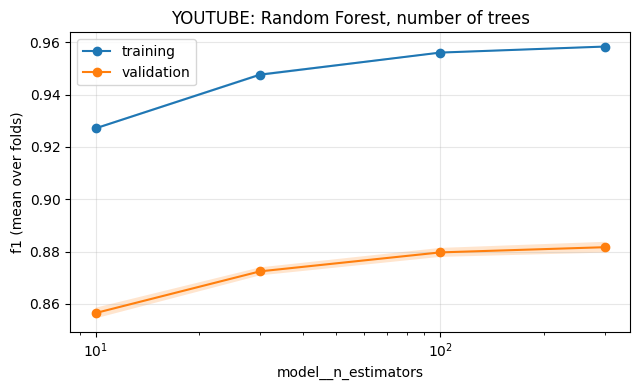

In [19]:
best = rf_searches[GROUP_APP].best_params_
rf = RandomForestClassifier(max_features="sqrt", max_samples=0.3, max_depth=best["model__max_depth"],
                            class_weight=best["model__class_weight"], random_state=SEED, n_jobs=1)
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_validation_curve(with_scaler(rf), X_train, make_ovr_target(y_train, GROUP_APP), "model__n_estimators",
                      [10, 30, 100, 300], folds, ax=ax)
ax.set_title(f"{GROUP_APP}: Random Forest, number of trees")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "rf_validation_curve_n_estimators.png", dpi=150)
plt.show()

Comments: the validation F1 grows from 0.857 with 10 trees to 0.880 with 100, and only to 0.882 with 300. So 100 trees
are already on the plateau, and the number of trees is not the reason why the forest does not beat the single tree.
The training F1 (0.96) stays well below 1 because each tree sees only 30% of the flows.

## Summary (Section 2.2, decision tree)

- **Best hyperparameters**: deep trees (`max_depth` 20 or `None`) with a small leaf size (`min_samples_leaf` 10 for 7
  apps, 1 for YOUTUBE, DROPBOX and CLOUDFLARE), Gini, and **no class weights** for 9 apps out of 10 (YOUTUBE:
  "balanced", but with the same F1 as `None`). They are saved in `results/section2/decision_tree.csv`.
- **Validation F1**: mean 0.783 over the 10 apps, from 0.92 (FACEBOOK) to 0.53 (TWITTER), always far above the random
  guess (0.03-0.34).
- **Rationale**: the apps are recognized mostly from specific values of a few features (initial TCP windows, max packet
  sizes, destination port) and from combinations of features. A tree can isolate a specific value with two splits and
  can combine features without any assumption on the shape of the boundary, so it needs to be deep and with small
  leaves. The overfitting of the deep trees is mild (the validation F1 is flat after depth 20); the gap between
  training and validation is larger for the hard apps, where many flows are similar to flows of other apps.
- **Class imbalance**: unlike the linear models, the tree does not need class weights: it builds leaves where the small
  app is the majority, and "balanced" turns too many mixed leaves into positives (TWITTER: recall 0.43 -> 0.70,
  precision 0.68 -> 0.26).
- **Features**: the same found in the EDA (initial windows, port 80, max packet sizes, timing for CLOUDFLARE). Some are
  possible shortcuts: the windows are signatures of the servers/proxy, and DROPBOX is recognized mostly from its
  inverted flows, a property of the capture.
- **Possible improvements** (small, ~0.005-0.015): pruning with `ccp_alpha` ~1e-5, `criterion="entropy"` for the
  hardest apps (SKYPE, TWITTER).
- **Random Forest** (extra): with 100 trees, 30% of the flows per tree and 8 features per split it does not beat the
  single tree (0.761): its 0.5 vote threshold is too conservative for the rare apps, and with class weights too
  permissive.

## Test set (Section 2.3)

The test set is not used in this notebook. The best classifier is chosen by C with `compare_models` on the validation
F1 of the 10 apps. If the decision tree is chosen, the trees retrained on the whole training set with the best
hyperparameters of each app (`searches[app].best_estimator_`, `refit=True`) are evaluated **once** on `X_test` with
`compute_metrics`.